# Extra · Salud y seguridad vial por zona

**Clustering the Star — Mercedes-Benz · III Malackathon 2026**

Objetivo: enriquecer la base de clientes de Mercedes-Benz con **datos públicos oficiales de salud y seguridad vial**
de Austria y Suiza, unirlos a nuestro CSV por **código postal** y medir qué relación tienen con los clientes, sus
vehículos y sus segmentos. Con ello se proponen acciones concretas de producto y servicio Mercedes-Benz.

La tabla por código postal que se genera aquí (`datos_externos_por_cp.csv`) la usa `features.py` para unir estos
indicadores a cada cliente desde el **Reto 1** (relaciones no evidentes), el **Reto 2** (por qué no entran en el modelo)
y el **Reto 4** (perfil de los segmentos).

| Indicador por zona | Austria 🇦🇹 | Suiza 🇨🇭 | Nivel |
|---|---|---|---|
| Accidentes con heridos (sin autopistas) por 1.000 habitantes | Statistik Austria, informe 2025 (tablas 90-91) | ASTRA, accidentes geolocalizados 2021-2025 | AT: distrito · CH: municipio |
| % de víctimas graves o mortales | Statistik Austria (tabla 90) | ASTRA (categoría de gravedad) | AT: distrito · CH: municipio |
| Mortalidad estandarizada por edad | Statistik Austria, 2023-2025 | — (no publicada bajo cantón) | AT: distrito |
| Distancia al hospital general de agudos más cercano | Ministerio de Sanidad (listado de hospitales) | BAG (indicadores de hospitales 2023) | Código postal |

**Principios:**
- Los indicadores describen la **zona**, nunca a la persona. No se infiere la salud de ningún cliente.
- Se usan para **priorizar campañas y servicios**, no para excluir clientes ni fijar precios.
- Los dos países miden distinto (AT cuenta personas, CH accidentes), así que cada zona se compara **dentro de su país**
  (percentil), igual que el poder adquisitivo en el Reto 2.

In [1]:
import json
import re
import zipfile
from pathlib import Path
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pdfplumber
from scipy.spatial import cKDTree
from scipy.stats import spearmanr

from features import cargar_datos, construir_pipeline, ajustar_kmeans, nombrar_segmentos, ORDEN_SEGMENTOS, COLORES_SEGMENTOS

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Datos externos

Todas las fuentes son oficiales y de libre uso (Statistik Austria: CC BY 4.0; swisstopo, ASTRA y BAG: condiciones de
opendata.swiss; directorio de hospitales del Ministerio de Sanidad de Austria: descarga pública sin licencia explícita).
Se descargan en `datos_externos/` (no se sube a git) solo si no existen ya. Organismo, dataset, periodo, enlace y
condiciones de uso de cada fichero: [`Fuentes_Datos_Externos.md`](Fuentes_Datos_Externos.md).

In [2]:
D = Path("datos_externos")
FUENTES = {
    "at_gemeinden/gemliste_knz.csv": "https://www.statistik.at/verzeichnis/reglisten/gemliste_knz.csv",
    "at_mortalidad/OGD_rate_kalwobez_GEST_KALWOCHE_STR_BZ_100.csv": "https://data.statistik.gv.at/data/OGD_rate_kalwobez_GEST_KALWOCHE_STR_BZ_100.csv",
    "at_accidentes/Strassenverkehrsunfaelle2025.pdf": "https://www.statistik.at/fileadmin/publications/Strassenverkehrsunfaelle2025.pdf",
    "at_hospitales/KA-Verzeichnis.xlsx": "https://www.sozialministerium.gv.at/dam/jcr:0a2c1fb9-68c3-4355-bf22-ff0d11c0186e/KA-Verzeichnis%202026-09-18.xlsx",
    "at_centroides/gem_mp.json": "https://www.statistik.gv.at/gs-open/GEODATA/ows?service=WFS&version=1.0.0&request=GetFeature&typeName=GEODATA:STATISTIK_AUSTRIA_GEM_MP_20230101&outputFormat=application/json",
    "ch_plz/plz.csv.zip": "https://data.geo.admin.ch/ch.swisstopo-vd.ortschaftenverzeichnis_plz/ortschaftenverzeichnis_plz/ortschaftenverzeichnis_plz_4326.csv.zip",
    "ch_accidentes/unfaelle.csv.zip": "https://data.geo.admin.ch/ch.astra.unfaelle-personenschaeden_alle/unfaelle-personenschaeden_alle/unfaelle-personenschaeden_alle_2056.csv.zip",
    "ch_hospitales/kzp23_data.xlsx": "https://opendata.bagnet.ch/?r=/download&path=L0taUC9renAyMy9renAyM19kYXRhLnhsc3g%3D",
}
for ruta, url in FUENTES.items():
    destino = D / ruta
    if not destino.exists():
        destino.parent.mkdir(parents=True, exist_ok=True)
        destino.write_bytes(urlopen(Request(url, headers={"User-Agent": "Mozilla/5.0"}), timeout=600).read())
pd.Series({r: f"{(D / r).stat().st_size / 1e6:,.2f} MB" for r in FUENTES}, name="tamaño").to_frame()

,tamaño
at_gemeinden/gemliste_knz.csv,0.08 MB
at_mortalidad/OGD_rate_kalwobez_GEST_KALWOCHE_STR_BZ_100.csv,4.97 MB
at_accidentes/Strassenverkehrsunfaelle2025.pdf,4.75 MB
at_hospitales/KA-Verzeichnis.xlsx,0.35 MB
at_centroides/gem_mp.json,0.54 MB
ch_plz/plz.csv.zip,0.19 MB
ch_accidentes/unfaelle.csv.zip,10.53 MB
ch_hospitales/kzp23_data.xlsx,1.07 MB


## 2. Austria

### 2.1 Código postal → municipio → distrito

La lista oficial de municipios incluye el código postal del ayuntamiento y otros códigos postales del municipio. Los 3
primeros dígitos del código de municipio son el **distrito político** (*Bezirk*).

Detalles que hay que resolver:
- **Un código postal puede pertenecer a varios municipios** (y distritos). Se asigna a uno: primero el municipio cuyo
  ayuntamiento usa ese código; si hay varios, la ciudad estatutaria (Steyr, Wels…) y después la ciudad.
- **Viena** figura como un único municipio, pero los accidentes vienen por sus 23 distritos. El código postal vienés
  indica el distrito (1**XX**0 = distrito XX).

In [3]:
gem = pd.read_csv(D / "at_gemeinden/gemliste_knz.csv", sep=";", skiprows=2, dtype=str)
gem = gem[gem["Gemeindekennziffer"].str.fullmatch(r"\d{5}", na=False)]
prioridad_estado = {"SR": 0, "ST": 1, "M": 2}
filas = []
for _, r in gem.iterrows():
    otros = [p for p in str(r["weitere Postleitzahlen"]).replace(",", " ").split() if p.isdigit()]
    for orden, plz in enumerate([r["PLZ des Gem.Amtes"]] + otros):
        filas.append({"plz": plz, "gkz": r["Gemeindekennziffer"], "es_ayuntamiento": orden == 0,
                      "prioridad": prioridad_estado.get(r["Status"], 3)})
at_plz = (pd.DataFrame(filas).sort_values(["plz", "es_ayuntamiento", "prioridad"], ascending=[True, False, True])
            .drop_duplicates("plz"))
at_plz["bezirk"] = at_plz["gkz"].str[:3]
viena = at_plz["bezirk"] == "900"
at_plz.loc[viena, "bezirk"] = "9" + at_plz.loc[viena, "plz"].str[1:3]
pd.Series({"códigos postales": len(at_plz), "municipios": gem.shape[0], "distritos": at_plz["bezirk"].nunique()})

códigos postales    2232
municipios          2114
distritos            116
dtype: int64

### 2.2 Accidentes por distrito (informe oficial 2025)

Statistik Austria publica los puntos de accidente solo como mapa (sin descarga masiva), pero el anexo del informe anual
trae las tablas por distrito. Se extraen del PDF:
- **Tabla 90**: accidentes, fallecidos, heridos graves y leves.
- **Tabla 91**: accidentes por tipo de vía, para **descontar autopistas y vías rápidas**. Un accidente en la autopista
  se cuenta en el distrito que atraviesa, aunque los implicados no vivan allí, y eso inflaría el riesgo de los
  distritos con autopista.

El PDF separa los miles con espacios ("1 196"), así que cada fila se reconstruye probando las particiones posibles y
quedándose con la que cumple las sumas de la tabla (fallecidos + heridos = víctimas; graves + leves = heridos…).

In [4]:
def partir(tokens, n, valida):
    tokens = ["0" if t in "-–" else t for t in tokens]
    sols = []
    def rec(i, acc):
        if len(acc) == n:
            if i == len(tokens):
                sols.append(acc)
            return
        for j in range(i + 1, min(i + 3, len(tokens)) + 1):
            g = tokens[i:j]
            if len(g[0]) <= 3 and all(len(t) == 3 for t in g[1:]):
                rec(j, acc + [int("".join(g))])
    rec(0, [])
    ok = [s for s in sols if valida(s)]
    return ok[0] if len(ok) == 1 else None

def leer_tabla(paginas, inicio, fin, n, valida, campos):
    filas, dentro, pendiente = [], False, ""
    for pagina in paginas:
        for linea in (pagina.extract_text() or "").split("\n"):
            if linea.startswith(inicio):
                dentro = True
                continue
            if linea.startswith(fin):
                dentro = False
            if not dentro:
                continue
            if re.match(r"^\d{3} \D+$", linea):           # nombre partido en dos líneas
                pendiente = linea
                continue
            if pendiente:
                linea, pendiente = pendiente + " " + linea, ""
            m = re.match(r"^(\d{3}) (.+?) ((?:[\d\-–]+ ?)+)$", linea)
            if m and (nums := partir(m.group(3).split(), n, valida)):
                filas.append({"bezirk": m.group(1), "nombre": re.sub(r"\s+", " ", m.group(2)), **dict(zip(campos, nums))})
    return pd.DataFrame(filas).drop_duplicates("bezirk")

pdf = pdfplumber.open(D / "at_accidentes/Strassenverkehrsunfaelle2025.pdf")
pags = pdf.pages[110:126]
t90 = leer_tabla(pags, "90 Unfälle", "91 Unfälle", 6,
                 lambda s: s[1] == s[2] + s[3] and s[3] == s[4] + s[5] and s[0] <= s[1],
                 ["accidentes", "victimas", "fallecidos", "heridos", "graves", "leves"])
t91 = leer_tabla(pags, "91 Unfälle", "92 Verletzte", 11,
                 lambda s: s[0] == s[1] + s[5] and s[1] == sum(s[2:5]) and s[5] == sum(s[6:11]),
                 ["total91", "urbano", "u1", "u2", "u3", "interurbano", "autopista", "via_rapida", "i1", "i2", "i3"])
at_acc = t90.merge(t91[["bezirk", "total91", "autopista", "via_rapida"]], on="bezirk", how="left")
print(f"Distritos: {len(at_acc)} · suma de accidentes {at_acc['accidentes'].sum():,} (total oficial 37.825) · "
      f"coinciden tablas 90 y 91: {(at_acc['total91'] == at_acc['accidentes']).mean():.0%}")

Distritos: 116 · suma de accidentes 37,825 (total oficial 37.825) · coinciden tablas 90 y 91: 100%


### 2.3 Mortalidad estandarizada por edad

Tasa semanal de mortalidad **estandarizada por edad** (corrige que un distrito tenga más población mayor) por distrito
de residencia. Se suma por año y se promedia **2023-2025**: se excluyen 2020-2022 para que la COVID no distorsione la
comparación, y 2026 porque está incompleto. Las semanas sin fallecidos no aparecen en el fichero y cuentan como 0.

In [5]:
mort = pd.read_csv(D / "at_mortalidad/OGD_rate_kalwobez_GEST_KALWOCHE_STR_BZ_100.csv", sep=";", dtype=str)
mort = mort[mort["C-SEXWO-0"] == "SEXWO-0"]
mort = mort.assign(anio=mort["C-KALWOCHE-0"].str[5:9].astype(int),
                   cod=mort["C-POLBEZKW-0"].str.replace("POLBEZKW-", ""),
                   tasa=pd.to_numeric(mort["F-RATE-1"].str.replace(",", "."), errors="coerce"))
mortalidad = (mort[mort["anio"].between(2023, 2025) & (mort["cod"].str.len() == 3)]
                .groupby(["cod", "anio"])["tasa"].sum().groupby("cod").mean().rename("mortalidad_std"))
print(f"Distritos con mortalidad: {len(mortalidad)} · media {mortalidad.mean():.2f} ‰ · rango {mortalidad.min():.2f}-{mortalidad.max():.2f} ‰")

Distritos con mortalidad: 94 · media 9.08 ‰ · rango 7.43-15.54 ‰


### 2.4 Distancia al hospital de agudos

Hospitales **generales de agudos** (sector *Akutversorgung*, tipo Eurostat HP 1.1) con su código postal. La distancia se
calcula entre centros de municipio, **en línea recta**: en valles alpinos el trayecto real es más largo.

In [6]:
ka = pd.read_excel(D / "at_hospitales/KA-Verzeichnis.xlsx", sheet_name="KA gesamt")
ka = ka[(ka["Versorgungssektor"] == "Akutversorgung") & ka["Typ gem. Eurostat"].astype(str).str.startswith("HP 1.1")]
ka["plz"] = ka["Adresse"].astype(str).str.extract(r",\s*(\d{4})\s")[0]   # el código postal va tras la coma
geo = json.load(open(D / "at_centroides/gem_mp.json", encoding="utf-8"))
centros_at = pd.DataFrame([{"gkz": f["properties"]["g_id"], "x": f["geometry"]["coordinates"][0] / 1000,
                            "y": f["geometry"]["coordinates"][1] / 1000} for f in geo["features"]]).set_index("gkz")
# Viena figura en la geometría dividida en sus 23 distritos (códigos 9XX01), no como el municipio 90001
gkz_geo = at_plz.set_index("plz")["gkz"]
gkz_geo = gkz_geo.where(gkz_geo != "90001", "9" + gkz_geo.index.str[1:3] + "01")
plz_xy = gkz_geo.map(lambda g: centros_at.loc[g, ["x", "y"]].tolist() if g in centros_at.index else None).dropna()
hosp_xy = np.array([plz_xy[p] for p in ka["plz"] if p in plz_xy.index])
dist_at, _ = cKDTree(hosp_xy).query(np.array(plz_xy.tolist()))
dist_hosp_at = pd.Series(dist_at, index=plz_xy.index, name="dist_hospital_km")
print(f"Hospitales de agudos: {len(ka)} (con coordenadas: {len(hosp_xy)}) · códigos postales con distancia: {len(dist_hosp_at):,}")

Hospitales de agudos: 107 (con coordenadas: 106) · códigos postales con distancia: 2,230


### 2.5 Tasas por habitante

La población de cada código postal viene de **nuestro propio CSV** (`population`): sumada da 9,09 millones en Austria
y 8,95 en Suiza, prácticamente la población oficial, así que sirve como denominador.

In [7]:
df = cargar_datos()
pob = df.dropna(subset=["zipcode", "population"]).drop_duplicates(["country_code", "zipcode"])[["country_code", "zipcode", "population"]]
pob["zipcode"] = pob["zipcode"].astype(str)
print("Población total del CSV:", pob.groupby("country_code")["population"].sum().map("{:,.0f}".format).to_dict())

pob_at = pob[pob["country_code"] == "AT"].merge(at_plz, left_on="zipcode", right_on="plz", how="left")
at_acc["poblacion"] = at_acc["bezirk"].map(pob_at.groupby("bezirk")["population"].sum())
at_acc["acc_sin_autopista"] = at_acc["accidentes"] - at_acc["autopista"].fillna(0) - at_acc["via_rapida"].fillna(0)
at_acc["tasa_accidentes"] = at_acc["acc_sin_autopista"] / at_acc["poblacion"] * 1000
at_acc["pct_graves"] = (at_acc["fallecidos"] + at_acc["graves"]) / at_acc["victimas"] * 100
at_acc["mortalidad_std"] = at_acc["bezirk"].map(lambda b: mortalidad.get("900" if b.startswith("9") else b))
display(at_acc[["tasa_accidentes", "pct_graves", "mortalidad_std"]].describe().T)
print("Distritos sin población:", at_acc.loc[at_acc["poblacion"].isna(), "nombre"].tolist())

Población total del CSV: {'AT': '9,093,158', 'CH': '8,946,567'}


,count,mean,std,min,25%,50%,75%,max
tasa_accidentes,116.00,4.04,1.67,1.88,3.24,3.94,4.54,17.29
pct_graves,116.00,18.04,6.58,5.10,12.20,18.76,22.95,31.55
mortalidad_std,116.00,9.09,0.93,7.43,8.65,9.16,9.33,15.54


Distritos sin población: []


## 3. Suiza

### 3.1 Código postal → municipio y coordenadas

El directorio oficial de localidades (swisstopo) da, para cada código postal, el municipio (número BFS), el % de
direcciones y las coordenadas. Un código postal puede abarcar varios municipios: se asigna al de **mayor % de
direcciones**.

In [8]:
z = zipfile.ZipFile(D / "ch_plz/plz.csv.zip")
loc = pd.read_csv(z.open("AMTOVZ_CSV_WGS84/AMTOVZ_CSV_WGS84.csv"), sep=";", dtype={"PLZ4": str})
loc["pct_dir"] = loc["Adressenanteil"].astype(str).str.replace("%", "").str.strip().astype(float)
ch_plz = (loc.sort_values("pct_dir", ascending=False).groupby("PLZ4")
             .agg(bfs=("BFS-Nr", "first"), lon=("E", "mean"), lat=("N", "mean"), municipios=("BFS-Nr", "nunique")))
ch_plz["x"] = ch_plz["lon"] * 111.32 * np.cos(np.radians(46.8))   # km (proyección local, suficiente a esta escala)
ch_plz["y"] = ch_plz["lat"] * 110.57
pd.Series({"códigos postales": len(ch_plz), "con varios municipios": int((ch_plz["municipios"] > 1).sum())})

códigos postales         3190
con varios municipios    1222
dtype: int64

### 3.2 Accidentes por municipio

Accidentes con heridos **2021-2025** (5 años, para reducir el ruido en municipios pequeños), **sin autopistas ni
autovías** (mismo motivo que en Austria). Gravedad: accidentes con fallecidos o heridos graves.

In [9]:
z = zipfile.ZipFile(D / "ch_accidentes/unfaelle.csv.zip")
acc = pd.read_csv(z.open("RoadTrafficAccidentLocations.csv"),
                  usecols=["AccidentSeverityCategory", "MunicipalityCode", "AccidentYear", "RoadType"])
acc = acc[acc["AccidentYear"].between(2021, 2025) & ~acc["RoadType"].isin(["rt430", "rt431"])]
ch_acc = acc.groupby("MunicipalityCode").agg(accidentes=("AccidentYear", "size"),
                                             graves=("AccidentSeverityCategory", lambda s: s.isin(["as1", "as2"]).sum()))
pob_ch = pob[pob["country_code"] == "CH"].merge(ch_plz[["bfs"]], left_on="zipcode", right_index=True, how="left")
ch_acc["poblacion"] = pob_ch.groupby("bfs")["population"].sum()
ch_acc["tasa_accidentes"] = ch_acc["accidentes"] / 5 / ch_acc["poblacion"] * 1000
ch_acc["pct_graves"] = ch_acc["graves"] / ch_acc["accidentes"] * 100
print(f"Accidentes 2021-2025 sin autopista: {len(acc):,} · municipios con accidentes: {len(ch_acc):,}")
ch_acc[["tasa_accidentes", "pct_graves"]].describe().T

Accidentes 2021-2025 sin autopista: 81,376 · municipios con accidentes: 2,037


,count,mean,std,min,25%,50%,75%,max
tasa_accidentes,"1,858.00",1.98,2.90,0.03,1.06,1.54,2.16,94.02
pct_graves,"2,037.00",27.67,18.72,0.00,16.67,25.00,36.00,100.00


### 3.3 Distancia al hospital de agudos

Hospitales **generales** (tipología BFS K111-K123: centros de referencia y de atención básica) y sus sedes.

In [10]:
xl = pd.ExcelFile(D / "ch_hospitales/kzp23_data.xlsx")
kz = xl.parse("KZ2023_KZP23")
generales = kz.loc[kz["Typ"].astype(str).str.match(r"K1[12]\d"), "Inst"]
sedes = xl.parse("Standorte_KZ2023_KZP23")
sedes = sedes[sedes["Inst"].isin(generales)]
sedes["plz"] = sedes["Ort_Standort"].astype(str).str.extract(r"\b(\d{4})\b")[0]
hosp = ch_plz.loc[ch_plz.index.intersection(sedes["plz"]), ["x", "y"]]
dist_ch, _ = cKDTree(hosp.to_numpy()).query(ch_plz[["x", "y"]].to_numpy())
dist_hosp_ch = pd.Series(dist_ch, index=ch_plz.index, name="dist_hospital_km")
print(f"Hospitales generales: {generales.nunique()} · sedes con código postal localizado: {len(hosp)}")

Hospitales generales: 101 · sedes con código postal localizado: 171


## 4. Tabla por código postal y unión con nuestro CSV

In [11]:
zona_at = at_plz[["plz", "bezirk"]].rename(columns={"plz": "zipcode", "bezirk": "zona"}).merge(
    at_acc[["bezirk", "tasa_accidentes", "pct_graves", "mortalidad_std"]], left_on="zona", right_on="bezirk", how="left").drop(columns="bezirk")
zona_at["dist_hospital_km"] = zona_at["zipcode"].map(dist_hosp_at)
zona_at["country_code"] = "AT"
zona_ch = ch_plz[["bfs"]].reset_index().rename(columns={"PLZ4": "zipcode", "bfs": "zona"})
zona_ch = zona_ch.merge(ch_acc[["tasa_accidentes", "pct_graves", "poblacion"]], left_on="zona", right_index=True, how="left")
# municipios muy pequeños: tasa muy ruidosa → sin dato
zona_ch.loc[zona_ch["poblacion"] < 1000, ["tasa_accidentes", "pct_graves"]] = np.nan
zona_ch = zona_ch.drop(columns="poblacion")
zona_ch["mortalidad_std"] = np.nan
zona_ch["dist_hospital_km"] = zona_ch["zipcode"].map(dist_hosp_ch)
zona_ch["country_code"] = "CH"
zona_ch["zona"] = zona_ch["zona"].astype(str)

zona = pd.concat([zona_at, zona_ch], ignore_index=True)
for c in ["tasa_accidentes", "pct_graves", "mortalidad_std", "dist_hospital_km"]:
    zona[f"{c}_pct_pais"] = zona.groupby("country_code")[c].rank(pct=True)
zona.round(4).to_csv("datos_externos_por_cp.csv", index=False)
print(f"Tabla por código postal guardada: {len(zona):,} filas")
zona.groupby("country_code")[["tasa_accidentes", "pct_graves", "mortalidad_std", "dist_hospital_km"]].median()

Tabla por código postal guardada: 5,422 filas


,tasa_accidentes,pct_graves,mortalidad_std,dist_hospital_km
country_code,,,,
AT,3.98,20.69,8.88,13.18
CH,1.63,25.00,NaN,5.80


In [12]:
# Unión con los clientes (1 fila por cliente) y su segmento
pipe = construir_pipeline()
X = pipe.fit_transform(df)
clientes = pipe.named_steps["agregar"].transform(df)
km = ajustar_kmeans(X)
clientes["segmento"] = pd.Categorical(pd.Series(km.labels_, index=clientes.index).map(
    nombrar_segmentos(pd.DataFrame(km.cluster_centers_, columns=X.columns))), categories=ORDEN_SEGMENTOS)
cp = df.drop_duplicates("client_id").set_index("client_id")["zipcode"].astype(str)
clientes["zipcode"] = cp
# features.py ya une estos indicadores (con percentiles entre clientes); aquí se usan los de la tabla recién
# construida, con percentiles por código postal, así que se quitan los de features para no duplicar columnas
clientes = clientes.drop(columns=[c for c in clientes.columns if c in zona.columns and c not in ("country_code", "zipcode")])
clientes = clientes.reset_index().merge(zona, on=["country_code", "zipcode"], how="left").set_index("client_id")

# Vehículo actual de cada cliente (para variables de seguridad: 4MATIC, SUV, antigüedad, asistentes obligatorios)
act = df[df["is_current_vehicle"]].copy()
reg = pd.to_datetime(act["date_of_first_registration"], errors="coerce")
act = act.assign(
    traccion_4matic=act["vehicle_type"].str.contains("4MATIC|4X4", case=False, na=False),
    suv=act["model_class"].str.contains(r"GL|EQB|EQC|G-Class|M-", na=False),
    anterior_gsr2=reg < "2024-07-07",
    antig=(reg.max() - reg).dt.days / 365.25)
veh = act.groupby("client_id")[["traccion_4matic", "suv", "anterior_gsr2", "antig"]].mean()
clientes = clientes.join(veh)
cob = clientes.groupby("country_code")[["tasa_accidentes", "dist_hospital_km", "mortalidad_std"]].apply(lambda g: g.notna().mean() * 100)
print("Cobertura (% de clientes con el indicador):")
cob.round(1)

Cobertura (% de clientes con el indicador):


,tasa_accidentes,dist_hospital_km,mortalidad_std
country_code,,,
AT,88.00,87.90,88.00
CH,89.80,92.80,0.00


**Cobertura:** casi todos los clientes reciben distancia al hospital y tasa de accidentes. La mortalidad solo existe
para Austria. Los clientes sin dato son los que no tienen código postal (Reto 1) o viven en municipios suizos de menos de
1.000 habitantes, donde la tasa sería ruido.

## 5. ¿Cómo son las zonas?

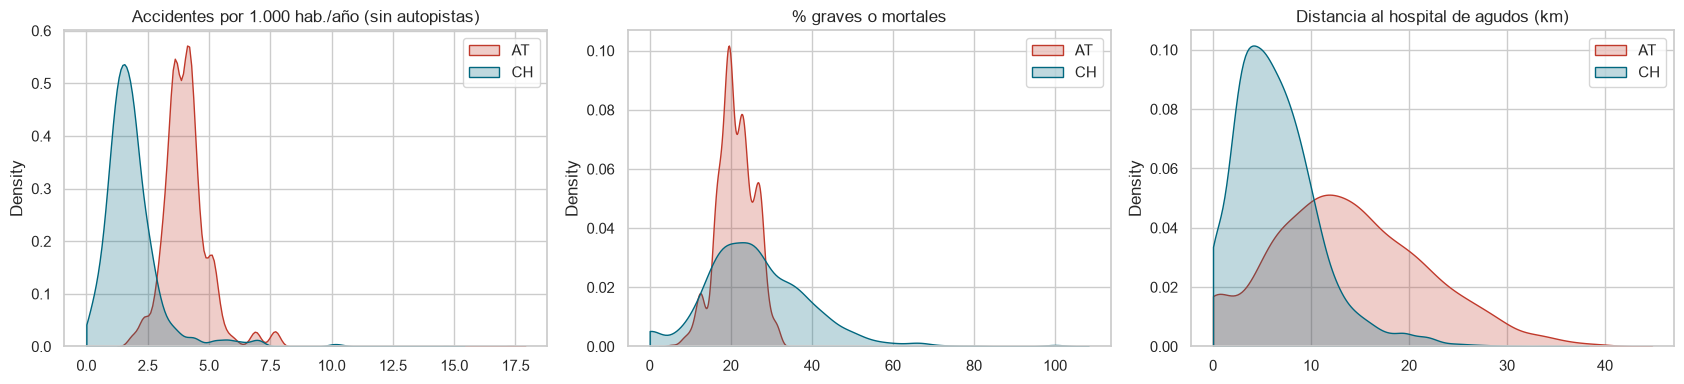

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (c, t) in zip(axes, [("tasa_accidentes", "Accidentes por 1.000 hab./año (sin autopistas)"),
                             ("pct_graves", "% graves o mortales"), ("dist_hospital_km", "Distancia al hospital de agudos (km)")]):
    for pais, color in [("AT", "#c0392b"), ("CH", "#00677F")]:
        sns.kdeplot(zona.loc[zona["country_code"] == pais, c].dropna(), ax=ax, label=pais, color=color, fill=True, alpha=.25, clip=(0, None))
    ax.set(title=t, xlabel="")
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Correlaciones con nuestros datos

### 6.1 A nivel de zona

Para cada zona (distrito en Austria, municipio en Suiza) se agregan los clientes que viven en ella y se calcula la
**correlación de Spearman** con los indicadores externos. Solo zonas con **30 clientes o más**, para que los porcentajes
sean estables. Se marca con * si p < 0,01.

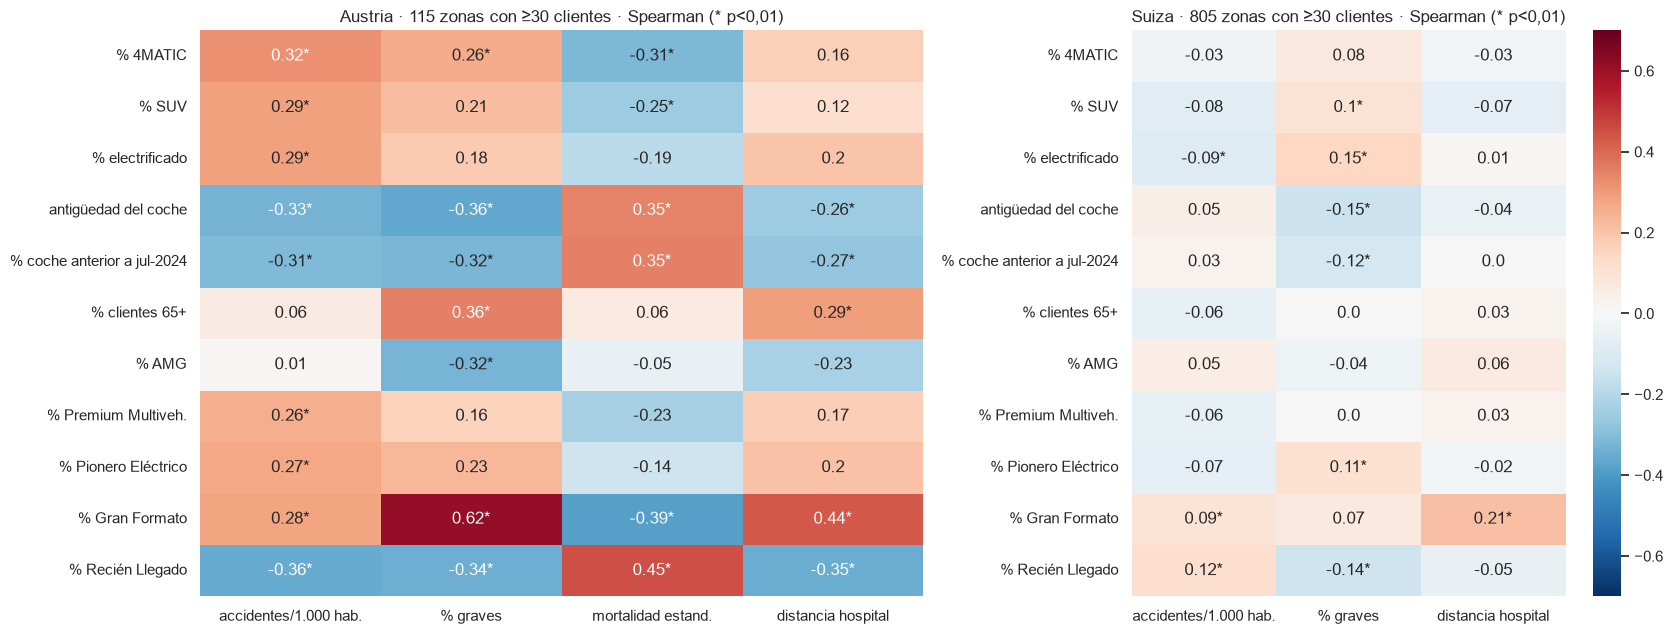

In [14]:
clientes["mayor_65"] = clientes["age_range"].eq("65+")
clientes["electrificado"] = clientes["pct_electrificado"]
for s in ["Premium Multivehículo", "Pionero Eléctrico", "Gran Formato", "Recién Llegado de Ocasión"]:
    clientes[f"seg: {s}"] = clientes["segmento"].eq(s)
vars_clientes = {"traccion_4matic": "% 4MATIC", "suv": "% SUV", "electrificado": "% electrificado", "antig": "antigüedad del coche",
                 "anterior_gsr2": "% coche anterior a jul-2024", "mayor_65": "% clientes 65+", "pct_amg": "% AMG",
                 "seg: Premium Multivehículo": "% Premium Multiveh.", "seg: Pionero Eléctrico": "% Pionero Eléctrico",
                 "seg: Gran Formato": "% Gran Formato", "seg: Recién Llegado de Ocasión": "% Recién Llegado"}
ext = {"tasa_accidentes": "accidentes/1.000 hab.", "pct_graves": "% graves", "mortalidad_std": "mortalidad estand.",
       "dist_hospital_km": "distancia hospital"}

def correlaciones(pais):
    sub = clientes[clientes["country_code"] == pais]
    zonas = sub.groupby("zona").agg(n=("segmento", "size"), **{k: (k, "mean") for k in list(vars_clientes) + list(ext)})
    zonas = zonas[zonas["n"] >= 30]
    rho, sig = pd.DataFrame(index=list(vars_clientes.values())), pd.DataFrame(index=list(vars_clientes.values()))
    for e, en in ext.items():
        if zonas[e].notna().sum() < 10:
            continue
        for v, vn in vars_clientes.items():
            ok = zonas[[e, v]].dropna()
            r, p = spearmanr(ok[e], ok[v])
            rho.loc[vn, en], sig.loc[vn, en] = r, p
    return rho.astype(float), sig.astype(float), len(zonas)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [4, 3]})
tablas = {}
for ax, pais in zip(axes, ["AT", "CH"]):
    rho, p, n = correlaciones(pais)
    tablas[pais] = (rho, p)
    etiquetas = rho.round(2).astype(str) + np.where(p < .01, "*", "")
    sns.heatmap(rho, annot=etiquetas, fmt="", cmap="RdBu_r", center=0, vmin=-.7, vmax=.7, ax=ax, cbar=pais == "CH")
    ax.set(title=f"{'Austria' if pais == 'AT' else 'Suiza'} · {n} zonas con ≥30 clientes · Spearman (* p<0,01)")
plt.tight_layout()
plt.show()

**Lectura · Austria (115 distritos, correlaciones moderadas y significativas):**
- **Mortalidad estandarizada (salud de la zona):** en los distritos con más mortalidad, los clientes tienen **coches más
  antiguos** (ρ = +0,35), más coches **anteriores a julio de 2024** (+0,35), es decir, sin los asistentes de seguridad
  obligatorios desde entonces, y más clientes **Recién Llegado de Ocasión** (+0,45). Tienen menos 4MATIC, SUV y Premium.
  La mortalidad refleja sobre todo el **nivel socioeconómico** de la zona, así que no es una relación causal. Pero
  señala dónde la flota de clientes Mercedes es **más antigua y menos protegida**.
- **% de víctimas graves (siniestralidad de carretera):** es el perfil **rural**. Más **Gran Formato** (+0,62), más
  clientes **65+** (+0,36), más 4MATIC (+0,26) y menos Recién Llegado (−0,34). Los accidentes fuera de ciudad son menos
  frecuentes pero mucho más graves.
- **Distancia al hospital:** más clientes **65+** (+0,29) y **Gran Formato** (+0,44) en las zonas más alejadas.
- **Accidentes por habitante:** mayor en ciudades y zonas turísticas alpinas, con más 4MATIC, SUV y electrificados.

**Lectura · Suiza (805 municipios):** las correlaciones son **débiles** (|ρ| ≤ 0,21). Las zonas suizas se diferencian
menos entre sí y, al ser municipios, las tasas son más ruidosas. Lo único algo consistente es que las zonas más
alejadas del hospital tienen más Gran Formato (+0,21), como en Austria.

⚠️ **Precauciones:**
1. **Correlación no es causalidad.** Una zona con más mortalidad no hace que sus clientes tengan coches viejos: ambas
   cosas dependen de un tercer factor (renta, ruralidad, edad de la población).
2. **Factor de confusión urbano/rural.** Gran parte de los patrones son el contraste ciudad frente a campo.
3. **Falacia ecológica.** Son relaciones entre **zonas**. No dicen que un cliente concreto esté en riesgo.
4. **Centros urbanos:** la tasa por habitante sobreestima el riesgo donde vive poca gente pero circula mucha (por
   ejemplo, el distrito 1 de Viena).

### 6.2 A nivel de segmento

Percentil medio (dentro de su país) de cada indicador para los clientes de cada segmento. 0,5 = zona típica de su país.

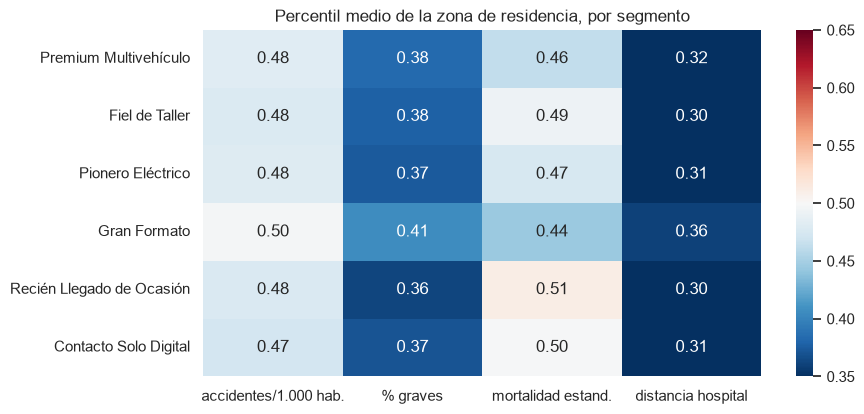

In [15]:
perfil = clientes.groupby("segmento", observed=True)[[f"{c}_pct_pais" for c in ext]].mean()
perfil.columns = list(ext.values())
# Nota: los percentiles se calculan sobre códigos postales; como los clientes se concentran en zonas urbanas, cercanas a
# hospitales, la media de distancia queda por debajo de 0,5 en todos los segmentos
plt.figure(figsize=(9, 4.5))
sns.heatmap(perfil, annot=True, fmt=".2f", cmap="RdBu_r", center=.5, vmin=.35, vmax=.65)
plt.title("Percentil medio de la zona de residencia, por segmento")
plt.ylabel("")
plt.show()

## 7. Del dato a la acción Mercedes-Benz

Se cuantifican los públicos objetivo cruzando el indicador de zona con lo que sabemos del cliente y su vehículo.

In [16]:
q = lambda c, v: clientes[f"{c}_pct_pais"] >= v
publicos = {
    "A · Zona de alta siniestralidad grave (cuartil superior de su país)": q("pct_graves", .75),
    "B · …y conduce un coche anterior a julio de 2024": q("pct_graves", .75) & (clientes["anterior_gsr2"] > 0),
    "C · Cliente 65+ con coche de 8+ años": clientes["mayor_65"] & (clientes["antig"] >= 8),
    "D · …y vive en zona de alta siniestralidad": clientes["mayor_65"] & (clientes["antig"] >= 8) & q("pct_graves", .75),
    "E · Lejos del hospital (decil más alejado de su país)": q("dist_hospital_km", .9),
    "F · …y tiene 65 años o más": q("dist_hospital_km", .9) & clientes["mayor_65"],
    "G · Zona de alta siniestralidad y sin 4MATIC": q("tasa_accidentes", .75) & (clientes["traccion_4matic"] == 0),
}
tabla_pub = pd.DataFrame({"clientes": {k: int(v.sum()) for k, v in publicos.items()},
                          "% de la base": {k: v.mean() * 100 for k, v in publicos.items()}})
tabla_pub

,clientes,% de la base
A · Zona de alta siniestralidad grave (cuartil superior de su país),21238,12.24
B · …y conduce un coche anterior a julio de 2024,14608,8.42
C · Cliente 65+ con coche de 8+ años,4869,2.81
D · …y vive en zona de alta siniestralidad,467,0.27
E · Lejos del hospital (decil más alejado de su país),6026,3.47
F · …y tiene 65 años o más,1121,0.65
G · Zona de alta siniestralidad y sin 4MATIC,12766,7.36


In [17]:
seg_pub = pd.DataFrame({k: clientes.loc[v, "segmento"].value_counts(normalize=True).reindex(ORDEN_SEGMENTOS) * 100
                        for k, v in publicos.items() if k[0] in "BDF"}).T
seg_pub.index = [i.split(" · ")[0] for i in seg_pub.index]
seg_pub.round(0)

segmento,Premium Multivehículo,Fiel de Taller,Pionero Eléctrico,Gran Formato,Recién Llegado de Ocasión,Contacto Solo Digital
B,13.00,34.00,12.00,9.00,22.00,10.00
D,7.00,40.00,2.00,2.00,33.00,15.00
F,10.00,31.00,18.00,7.00,19.00,14.00


**Lectura por segmento:** las diferencias entre segmentos son pequeñas (los indicadores de zona apenas separan
segmentos), salvo **Gran Formato**, que vive en zonas algo más alejadas del hospital y con accidentes más graves. Por
eso los indicadores externos no sustituyen a la segmentación: la **complementan**, señalando dentro de cada segmento
qué clientes priorizar.

## 8. Propuestas para Mercedes-Benz

| Público (tabla anterior) | Por qué (dato) | Acción Mercedes-Benz | Segmentos con más peso |
|---|---|---|---|
| **B** · Zona de siniestralidad grave + coche anterior a jul-2024 (~14.600 clientes) | Las zonas con más víctimas graves son rurales y de carretera; esos coches no llevan obligatoriamente los asistentes de 2024 | **Campaña "Seguridad activa"**: renovación con Active Brake Assist, Active Lane Keeping Assist, ATTENTION ASSIST y PRE-SAFE®; para quien no renueva, **revisión de seguridad** (frenos, neumáticos, luces) en el taller oficial | Fiel de Taller (34 %), Recién Llegado (22 %) |
| **C/D** · 65+ con coche de 8+ años (~4.900; ~470 en zonas de riesgo) | Los mayores tienen más coches antiguos; el riesgo de accidente crece a partir de los 80 años (KFV) | Prueba de conducción de modelos con **asistentes de aparcamiento y DISTRONIC**; **Mercedes-Benz Certified** (seminuevos con asistentes); cursos de conducción con ÖAMTC (AT) o TCS (CH) | Fiel de Taller (41 %), Recién Llegado (33 %) |
| **E/F** · Decil más alejado del hospital (~6.000; ~1.100 con 65+) | Zonas rurales con más población mayor | Promoción de **Mercedes me connect**: llamada de emergencia automática, asistencia en carretera y avisos de mantenimiento; activación gratuita en el taller | Fiel de Taller, Pionero Eléctrico |
| **G** · Zona de muchos accidentes y sin 4MATIC (~12.800) | Las zonas con más accidentes tienen más 4MATIC; quien no lo tiene es candidato | Ofertas de **4MATIC** en la renovación y **paquete de invierno** (neumáticos y revisión) en zonas alpinas | Todos |
| Distritos con más mortalidad (Austria) | Flota de clientes más antigua y más Recién Llegado | Priorizar las **ofertas de renovación con financiación de entrada** y la captación al taller oficial en esos distritos | Recién Llegado de Ocasión |

**Cómo usarlo de forma responsable:**
- El indicador de zona decide **dónde y qué** comunicar (prioridad, mensaje, horario de campañas), nunca **a quién
  excluir** ni el precio.
- Mensajes en positivo ("más seguridad en tus trayectos"), **sin mencionar** la siniestralidad o la salud de su zona.
- Respetar los **canales consentidos** (Reto 4): el público "Contacto Solo Digital" solo por email.

## 9. Conclusiones

- Hemos unido a nuestro CSV, por código postal, **cuatro indicadores oficiales** de salud y seguridad vial de **Austria y
  Suiza** (accidentes, gravedad, mortalidad estandarizada y distancia al hospital), con cobertura de ~88-93 % de los
  clientes.
- En **Austria** aparecen relaciones moderadas y útiles: zonas con peor salud ↔ coches más antiguos y menos protegidos;
  zonas con accidentes más graves y lejos del hospital ↔ perfil rural, mayor y de furgoneta. En **Suiza** las relaciones
  son débiles.
- Los indicadores **no cambian la segmentación**, pero permiten **priorizar** dentro de ella públicos concretos y
  cuantificados para campañas de seguridad (asistentes, 4MATIC, revisiones, Mercedes me connect).
- La tabla por código postal (`datos_externos_por_cp.csv`) queda en el repositorio para que el equipo la reutilice sin
  descargar los datos brutos.